Section 2:
Code and Data preparation.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from torchvision.transforms import v2
from torchvision.io import decode_image, ImageReadMode

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [2]:
trainDf = pd.read_csv('./data/train_labels.csv')
testDf = pd.read_csv('./data/test_labels.csv')
valDf = pd.read_csv('./data/val_labels.csv')

In [3]:
K = set(trainDf.breed) | set(testDf.breed) | set(valDf.breed)
print(len(K),K)
clss_idx = {b:i for i,b in enumerate(K)}
Y = torch.tensor([clss_idx[b] for b in trainDf.breed]).to(device)

120 {'english_foxhound', 'vizsla', 'pug', 'affenpinscher', 'lakeland_terrier', 'black-and-tan_coonhound', 'border_terrier', 'kuvasz', 'norwich_terrier', 'bouvier_des_flandres', 'scottish_deerhound', 'norwegian_elkhound', 'curly-coated_retriever', 'wire-haired_fox_terrier', 'bloodhound', 'dingo', 'norfolk_terrier', 'toy_poodle', 'old_english_sheepdog', 'welsh_springer_spaniel', 'italian_greyhound', 'kelpie', 'rottweiler', 'otterhound', 'yorkshire_terrier', 'boxer', 'samoyed', 'scotch_terrier', 'sealyham_terrier', 'pomeranian', 'african_hunting_dog', 'brabancon_griffon', 'briard', 'ibizan_hound', 'borzoi', 'irish_water_spaniel', 'airedale', 'standard_poodle', 'shetland_sheepdog', 'cocker_spaniel', 'clumber', 'entlebucher', 'chesapeake_bay_retriever', 'doberman', 'mexican_hairless', 'lhasa', 'pekinese', 'siberian_husky', 'brittany_spaniel', 'redbone', 'chihuahua', 'irish_terrier', 'west_highland_white_terrier', 'miniature_poodle', 'tibetan_mastiff', 'collie', 'irish_wolfhound', 'saint_ber

In [4]:
efficientNet = models.efficientnet_v2_s(weights=None)
efficientNet.to(device)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  

In [5]:
resize = v2.Resize((100, 100), antialias=True)
# decode_image gives RGB, channel-first (C,H,W) uint8 tensors
imgs = torch.stack([
    resize(decode_image(f'./data/train/images/{p}.jpg', mode=ImageReadMode.RGB))
    for p in trainDf.id
]).to(device)  # uint8, N,C,H,W
print(imgs.shape, imgs.dtype)

torch.Size([7155, 3, 100, 100]) torch.uint8


In [6]:
x = imgs.float() / 255
mean = x.mean(dim=(0, 2, 3))
std = x.std(dim=(0, 2, 3))
del x
print("Mean of the training set is:", mean, "Standard Deviation of training set is:", std)

Mean of the training set is: tensor([0.4772, 0.4528, 0.3928], device='cuda:0') Standard Deviation of training set is: tensor([0.2534, 0.2480, 0.2523], device='cuda:0')


In [7]:
import torch.nn.functional as F

norm = v2.Normalize(mean.tolist(), std.tolist())
PAD = 12

def augment(xb):
    # xb: uint8 (B,C,H,W) on the GPU. Per-image random flip + random crop, no Python loop.
    B, _, H, W = xb.shape
    dev = xb.device
    flip = torch.rand(B, device=dev) < 0.5
    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)   # horizontal flip, p=0.5
    xp = F.pad(xb, (PAD, PAD, PAD, PAD))                          # zero padding of 12
    dy = torch.randint(0, 2 * PAD + 1, (B,), device=dev)          # per-image crop offsets
    dx = torch.randint(0, 2 * PAD + 1, (B,), device=dev)
    rows = dy[:, None] + torch.arange(H, device=dev)              # (B,H)
    cols = dx[:, None] + torch.arange(W, device=dev)              # (B,W)
    b = torch.arange(B, device=dev)[:, None, None]
    out = xp[b, :, rows[:, :, None], cols[:, None, :]]            # (B,H,W,C)
    return out.permute(0, 3, 1, 2)                                # back to (B,C,H,W)

def prep(xb, train=False):
    if train:
        xb = augment(xb)
    return norm(xb.float() / 255)

xb = prep(imgs[:64], train=True)
print(xb.shape, xb.mean(dim=(0, 2, 3)), xb.std(dim=(0, 2, 3)))

torch.Size([64, 3, 100, 100]) tensor([-0.2728, -0.2659, -0.1782], device='cuda:0') tensor([1.1017, 1.0890, 1.0556], device='cuda:0')


In [ ]:
batch_size = 128
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

In [9]:
def train(X:torch.Tensor,Y:torch.Tensor,criterion:nn.CrossEntropyLoss,optimizer:torch.optim.Optimizer,scheduler:torch.optim.lr_scheduler.LRScheduler,epochs=15,lr=0.01,Xv=None,Yv=None):
    losses,accuracy,val_losses,val_accuracy=[],[],[],[]
    for epoch in range(epochs):
        efficientNet.train()
        perm = torch.randperm(len(X),device=device)
        total_loss,correct=0,0
        for i in range(0,X.shape[0],batch_size):
            idx = perm[i:i+batch_size]
            x,y = prep(X[idx],train=True),Y[idx]
            optimizer.zero_grad(set_to_none=True)
            output = efficientNet(x)
            loss = criterion(output,y)
            loss.backward()
            optimizer.step()
            if(scheduler is not None):
                scheduler.step()
            total_loss += loss.item() * len(idx)
            correct += (output.argmax(1) == y).sum().item()
        losses.append(total_loss/len(X))
        accuracy.append(correct/len(X))
        msg = f'epoch {epoch}: loss {losses[-1]:.4f} acc {accuracy[-1]:.4f}'
        if Xv is not None:
            vl,va = eval(Xv,Yv,criterion)
            val_losses.append(vl)
            val_accuracy.append(va)
            msg += f' val_loss {vl:.4f} val_acc {va:.4f}'
        print(msg)
    return losses,accuracy,val_losses,val_accuracy


def eval(X:torch.Tensor,Y:torch.Tensor,criterion:nn.CrossEntropyLoss):
    efficientNet.eval()
    total_loss,correct = 0,0
    with torch.no_grad():
        for i in range(0,len(X),batch_size):
            x,y = X[i:i+batch_size],Y[i:i+batch_size]
            output = efficientNet(x)
            loss = criterion(output,y)
            total_loss+=loss.item()*len(y)
            correct += (output.argmax(1)==y).sum().item()
    return total_loss/len(X),correct/len(X)


In [10]:
def plot_curves(losses, val_losses, accuracy, val_accuracy, lr=None):
    ep = range(1, len(losses) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    a1.plot(ep, losses, label='train')
    a1.plot(ep, val_losses, label='val')
    a1.set(xlabel='epoch', ylabel='loss', title=f'Loss vs epoch (lr={lr})')
    a1.legend()
    a2.plot(ep, accuracy, label='train')
    a2.plot(ep, val_accuracy, label='val')
    a2.set(xlabel='epoch', ylabel='accuracy', title=f'Accuracy vs epoch (lr={lr})')
    a2.legend()
    plt.tight_layout()
    plt.show()


In [11]:
val_imgs = torch.stack([
    resize(decode_image(f'./data/val/images/{p}.jpg',mode=ImageReadMode.RGB))
    for p in valDf.id
]).to(device)
print(val_imgs.shape)

torch.Size([1533, 3, 100, 100])


In [ ]:
X_train = imgs  # raw uint8; augmented fresh every batch inside train()
X_val = prep(val_imgs,False)
Y_train = torch.tensor([clss_idx[b] for b in trainDf.breed], dtype=torch.long, device=device)
Y_val   = torch.tensor([clss_idx[b] for b in valDf.breed],   dtype=torch.long, device=device)

Section 3: Learning Rates

#1: LR = 0.5

epoch 0: loss 6.4226 acc 0.0105 val_loss 5.6074 val_acc 0.0078
epoch 1: loss 5.3756 acc 0.0094 val_loss 5.2730 val_acc 0.0111
epoch 2: loss 5.2759 acc 0.0161 val_loss 5.2456 val_acc 0.0209
epoch 3: loss 5.1938 acc 0.0211 val_loss 5.1973 val_acc 0.0183
epoch 4: loss 5.1179 acc 0.0229 val_loss 5.2091 val_acc 0.0241
epoch 5: loss 5.0490 acc 0.0299 val_loss 5.1175 val_acc 0.0274
epoch 6: loss 4.9864 acc 0.0335 val_loss 5.0013 val_acc 0.0320
epoch 7: loss 4.9373 acc 0.0401 val_loss 5.0397 val_acc 0.0398
epoch 8: loss 4.8868 acc 0.0446 val_loss 4.9836 val_acc 0.0489
epoch 9: loss 4.8244 acc 0.0539 val_loss 4.9250 val_acc 0.0476
epoch 10: loss 4.7832 acc 0.0570 val_loss 4.8722 val_acc 0.0450
epoch 11: loss 4.7277 acc 0.0588 val_loss 4.8787 val_acc 0.0437
epoch 12: loss 4.6749 acc 0.0622 val_loss 4.9282 val_acc 0.0607
epoch 13: loss 4.6206 acc 0.0728 val_loss 4.8930 val_acc 0.0574
epoch 14: loss 4.5881 acc 0.0798 val_loss 4.8432 val_acc 0.0541


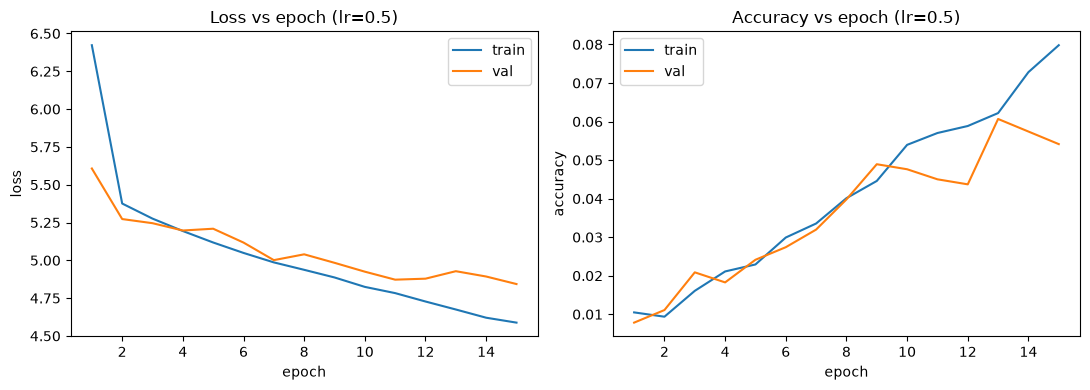

In [13]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.5)
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler=None,epochs=15, Xv=X_val, Yv=Y_val,lr=0.5)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.5)

LR=0.05

epoch 0: loss 6.9246 acc 0.0045 val_loss 6.8622 val_acc 0.0111
epoch 1: loss 6.8174 acc 0.0082 val_loss 6.7438 val_acc 0.0098
epoch 2: loss 6.5027 acc 0.0113 val_loss 6.1860 val_acc 0.0111
epoch 3: loss 6.0151 acc 0.0094 val_loss 5.7365 val_acc 0.0098
epoch 4: loss 5.6632 acc 0.0102 val_loss 5.5628 val_acc 0.0098
epoch 5: loss 5.4659 acc 0.0112 val_loss 5.4437 val_acc 0.0124
epoch 6: loss 5.3814 acc 0.0110 val_loss 5.3690 val_acc 0.0124
epoch 7: loss 5.3317 acc 0.0105 val_loss 5.3283 val_acc 0.0163
epoch 8: loss 5.2966 acc 0.0120 val_loss 5.2731 val_acc 0.0170
epoch 9: loss 5.2423 acc 0.0148 val_loss 5.2080 val_acc 0.0196
epoch 10: loss 5.1746 acc 0.0190 val_loss 5.1437 val_acc 0.0235
epoch 11: loss 5.1108 acc 0.0232 val_loss 5.0863 val_acc 0.0307
epoch 12: loss 5.0521 acc 0.0250 val_loss 5.1183 val_acc 0.0248
epoch 13: loss 4.9899 acc 0.0316 val_loss 4.9856 val_acc 0.0339
epoch 14: loss 4.9521 acc 0.0342 val_loss 4.9880 val_acc 0.0352


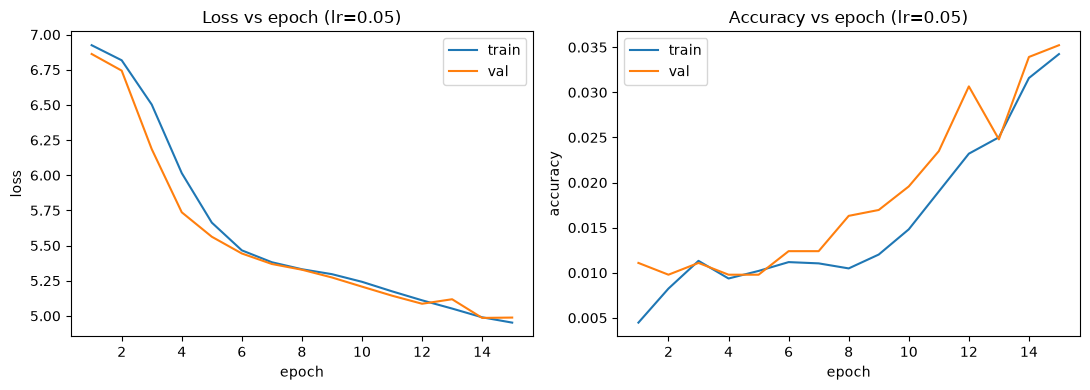

In [15]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.05)
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler=None,epochs=15, Xv=X_val, Yv=Y_val,lr=0.05)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.05)

LR=0.001

epoch 0: loss 6.9498 acc 0.0013 val_loss 6.9066 val_acc 0.0072
epoch 1: loss 6.9432 acc 0.0021 val_loss 6.9085 val_acc 0.0026
epoch 2: loss 6.9390 acc 0.0024 val_loss 6.9098 val_acc 0.0020
epoch 3: loss 6.9333 acc 0.0021 val_loss 6.9107 val_acc 0.0026
epoch 4: loss 6.9234 acc 0.0018 val_loss 6.9103 val_acc 0.0026
epoch 5: loss 6.9156 acc 0.0035 val_loss 6.9246 val_acc 0.0052
epoch 6: loss 6.9065 acc 0.0034 val_loss 6.9264 val_acc 0.0065
epoch 7: loss 6.9072 acc 0.0025 val_loss 6.9205 val_acc 0.0065
epoch 8: loss 6.8953 acc 0.0035 val_loss 6.9163 val_acc 0.0065
epoch 9: loss 6.8939 acc 0.0041 val_loss 6.9249 val_acc 0.0059
epoch 10: loss 6.8902 acc 0.0046 val_loss 6.9085 val_acc 0.0065
epoch 11: loss 6.8812 acc 0.0049 val_loss 6.8974 val_acc 0.0065
epoch 12: loss 6.8752 acc 0.0055 val_loss 6.8931 val_acc 0.0052
epoch 13: loss 6.8701 acc 0.0045 val_loss 6.8928 val_acc 0.0052
epoch 14: loss 6.8610 acc 0.0073 val_loss 6.8901 val_acc 0.0052


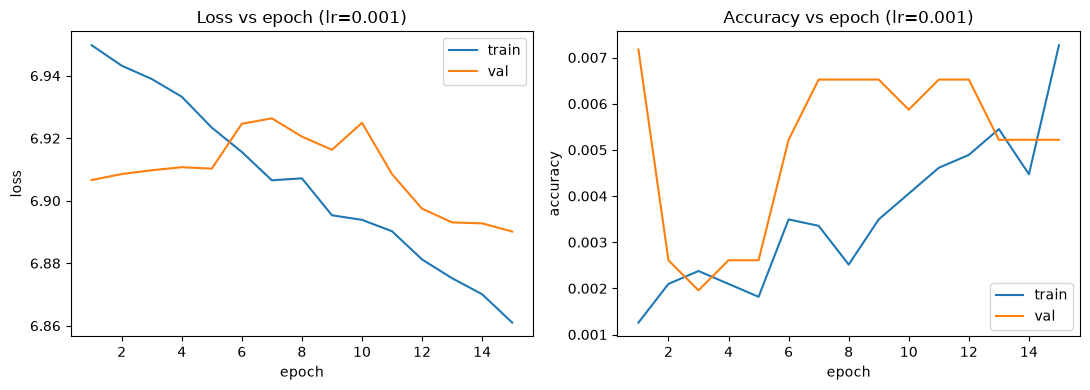

In [16]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.001)
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler=None,epochs=15, Xv=X_val, Yv=Y_val,lr=0.001)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.001)

Here the best results are given by LR = 0.05 so moving forward we will use this initial LR.

#SECTION 04: Scheduled Learning Rates

In [17]:
import math
from torch.optim.lr_scheduler import CosineAnnealingLR
num_epochs = 300
steps_per_epoch = math.ceil(len(X_train) / batch_size)

Without Cosine Annealing and 300 epochs

epoch 0: loss 6.4932 acc 0.0094 val_loss 5.7328 val_acc 0.0111
epoch 1: loss 5.3884 acc 0.0099 val_loss 5.3158 val_acc 0.0091
epoch 2: loss 5.2636 acc 0.0172 val_loss 5.2706 val_acc 0.0183
epoch 3: loss 5.1962 acc 0.0193 val_loss 5.2033 val_acc 0.0215
epoch 4: loss 5.1260 acc 0.0222 val_loss 5.1480 val_acc 0.0241
epoch 5: loss 5.0534 acc 0.0295 val_loss 5.0155 val_acc 0.0359
epoch 6: loss 4.9668 acc 0.0362 val_loss 4.9608 val_acc 0.0365
epoch 7: loss 4.9156 acc 0.0387 val_loss 5.0603 val_acc 0.0431
epoch 8: loss 4.8455 acc 0.0470 val_loss 4.8898 val_acc 0.0450
epoch 9: loss 4.7934 acc 0.0551 val_loss 4.8830 val_acc 0.0483
epoch 10: loss 4.7468 acc 0.0590 val_loss 4.8755 val_acc 0.0535
epoch 11: loss 4.6969 acc 0.0616 val_loss 4.8612 val_acc 0.0476
epoch 12: loss 4.6434 acc 0.0703 val_loss 4.9273 val_acc 0.0541
epoch 13: loss 4.5970 acc 0.0770 val_loss 4.8998 val_acc 0.0574
epoch 14: loss 4.5585 acc 0.0857 val_loss 4.9162 val_acc 0.0620
epoch 15: loss 4.5231 acc 0.0908 val_loss 4.7426 v

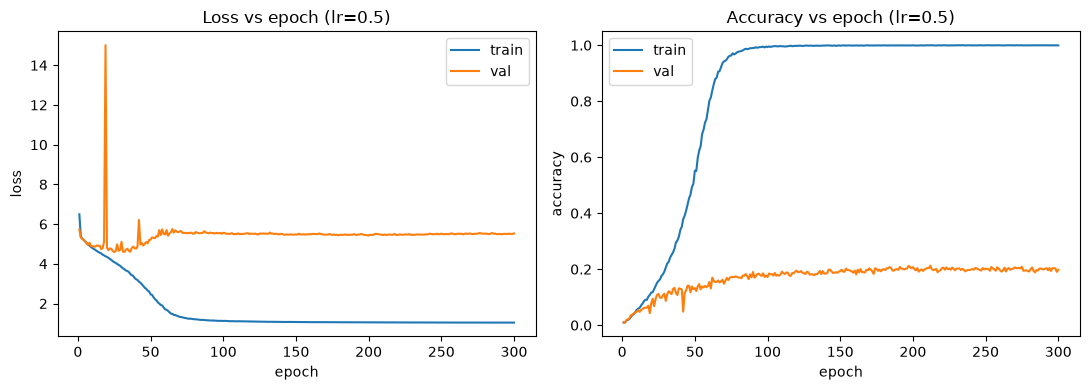

In [18]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.5)
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler=None,epochs=num_epochs,lr=0.5,Xv=X_val,Yv=Y_val)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.5)

With Cosine Annealing and 300 epochs

epoch 0: loss 6.4370 acc 0.0098 val_loss 6.2378 val_acc 0.0078
epoch 1: loss 5.3666 acc 0.0105 val_loss 5.2776 val_acc 0.0117
epoch 2: loss 5.2604 acc 0.0172 val_loss 5.2608 val_acc 0.0157
epoch 3: loss 5.2114 acc 0.0182 val_loss 5.2480 val_acc 0.0163
epoch 4: loss 5.1684 acc 0.0228 val_loss 5.1669 val_acc 0.0176
epoch 5: loss 5.1142 acc 0.0253 val_loss 5.0852 val_acc 0.0320
epoch 6: loss 5.0497 acc 0.0309 val_loss 5.1135 val_acc 0.0287
epoch 7: loss 4.9963 acc 0.0342 val_loss 4.9852 val_acc 0.0437
epoch 8: loss 4.9265 acc 0.0405 val_loss 4.9495 val_acc 0.0496
epoch 9: loss 4.8573 acc 0.0528 val_loss 4.9137 val_acc 0.0535


epoch 10: loss 4.7994 acc 0.0594 val_loss 4.8616 val_acc 0.0444
epoch 11: loss 4.7372 acc 0.0598 val_loss 4.8763 val_acc 0.0541
epoch 12: loss 4.6791 acc 0.0661 val_loss 4.7927 val_acc 0.0672
epoch 13: loss 4.6213 acc 0.0702 val_loss 4.8553 val_acc 0.0613
epoch 14: loss 4.5734 acc 0.0820 val_loss 4.8682 val_acc 0.0600
epoch 15: loss 4.5233 acc 0.0889 val_loss 4.7022 val_acc 0.0802
epoch 16: loss 4.4534 acc 0.0904 val_loss 4.6913 val_acc 0.0750
epoch 17: loss 4.4173 acc 0.0999 val_loss 4.6793 val_acc 0.0757
epoch 18: loss 4.3765 acc 0.1073 val_loss 4.6956 val_acc 0.0802
epoch 19: loss 4.3165 acc 0.1180 val_loss 4.7097 val_acc 0.0874
epoch 20: loss 4.2737 acc 0.1242 val_loss 4.6476 val_acc 0.0789
epoch 21: loss 4.2198 acc 0.1289 val_loss 4.6314 val_acc 0.0894
epoch 22: loss 4.1825 acc 0.1353 val_loss 4.6226 val_acc 0.0913
epoch 23: loss 4.1093 acc 0.1511 val_loss 4.6301 val_acc 0.1037
epoch 24: loss 4.0910 acc 0.1597 val_loss 4.6239 val_acc 0.1076
epoch 25: loss 4.0306 acc 0.1679 val_los

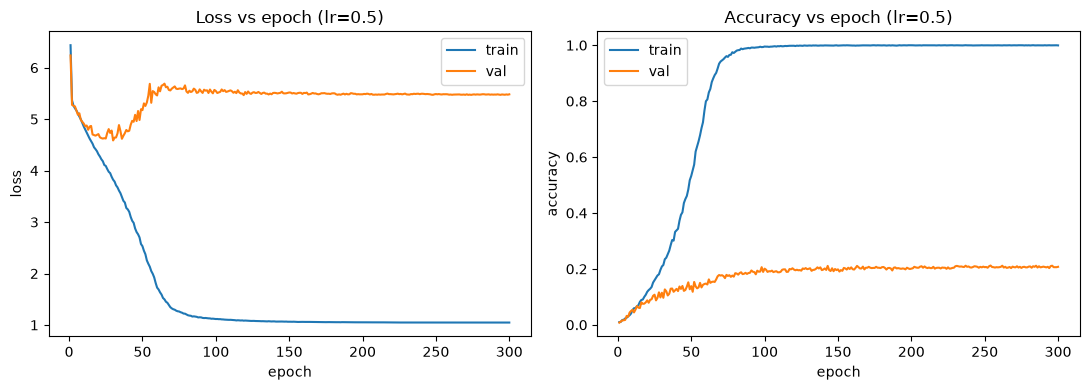

In [19]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.5)
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs * steps_per_epoch)  # stepped per batch in train()
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler,num_epochs,0.01,X_val,Y_val)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.5)

Section 5: Weight Decay

weight decay lambda = 5 * 10-4

epoch 0: loss 6.5036 acc 0.0084 val_loss 5.7146 val_acc 0.0144
epoch 1: loss 5.4158 acc 0.0096 val_loss 5.3145 val_acc 0.0085
epoch 2: loss 5.3109 acc 0.0092 val_loss 5.2954 val_acc 0.0124
epoch 3: loss 5.2969 acc 0.0095 val_loss 5.2702 val_acc 0.0130
epoch 4: loss 5.2825 acc 0.0116 val_loss 5.2496 val_acc 0.0157
epoch 5: loss 5.2527 acc 0.0145 val_loss 5.2186 val_acc 0.0144
epoch 6: loss 5.1999 acc 0.0179 val_loss 5.2104 val_acc 0.0209
epoch 7: loss 5.1655 acc 0.0207 val_loss 5.1295 val_acc 0.0274
epoch 8: loss 5.1099 acc 0.0232 val_loss 5.1594 val_acc 0.0202
epoch 9: loss 5.0582 acc 0.0270 val_loss 5.0599 val_acc 0.0294
epoch 10: loss 4.9901 acc 0.0327 val_loss 5.0778 val_acc 0.0254
epoch 11: loss 4.9385 acc 0.0361 val_loss 4.9737 val_acc 0.0313
epoch 12: loss 4.8838 acc 0.0416 val_loss 5.0551 val_acc 0.0483
epoch 13: loss 4.8321 acc 0.0493 val_loss 4.9537 val_acc 0.0522
epoch 14: loss 4.7790 acc 0.0512 val_loss 4.7961 val_acc 0.0535
epoch 15: loss 4.7430 acc 0.0530 val_loss 4.7953 v

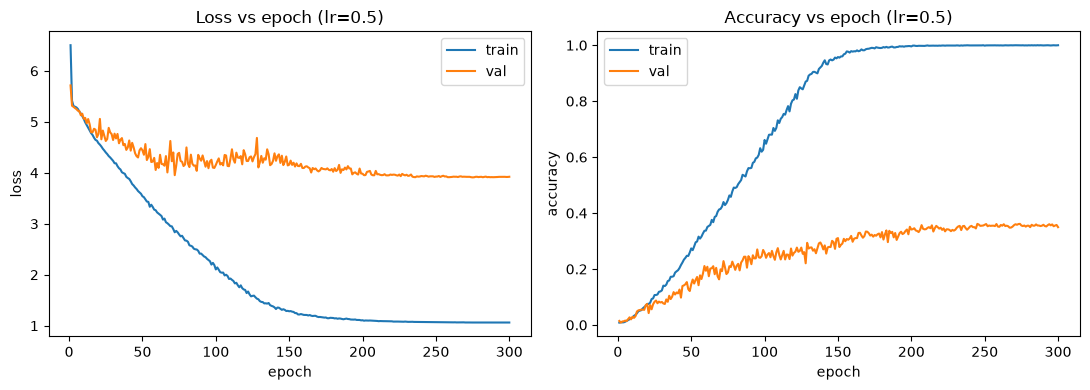

In [20]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.5,weight_decay=5*(10**-4))
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs * steps_per_epoch)  # stepped per batch in train()
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler,num_epochs,0.01,X_val,Y_val)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.5)

weight decay lambda = 1 * 10-4

epoch 0: loss 6.4329 acc 0.0081 val_loss 5.6392 val_acc 0.0124
epoch 1: loss 5.3830 acc 0.0098 val_loss 5.2998 val_acc 0.0085
epoch 2: loss 5.3050 acc 0.0122 val_loss 5.2667 val_acc 0.0170
epoch 3: loss 5.2502 acc 0.0152 val_loss 5.3137 val_acc 0.0117
epoch 4: loss 5.1618 acc 0.0190 val_loss 5.1478 val_acc 0.0254
epoch 5: loss 5.1073 acc 0.0231 val_loss 5.1428 val_acc 0.0261
epoch 6: loss 5.0389 acc 0.0282 val_loss 5.0626 val_acc 0.0326
epoch 7: loss 4.9879 acc 0.0300 val_loss 5.1636 val_acc 0.0333
epoch 8: loss 4.9345 acc 0.0382 val_loss 4.9179 val_acc 0.0411
epoch 9: loss 4.8614 acc 0.0461 val_loss 4.8956 val_acc 0.0378
epoch 10: loss 4.8193 acc 0.0530 val_loss 4.9275 val_acc 0.0424
epoch 11: loss 4.7517 acc 0.0560 val_loss 4.9247 val_acc 0.0463
epoch 12: loss 4.7078 acc 0.0665 val_loss 4.8671 val_acc 0.0515
epoch 13: loss 4.6464 acc 0.0688 val_loss 4.9689 val_acc 0.0548
epoch 14: loss 4.6068 acc 0.0759 val_loss 4.7754 val_acc 0.0691
epoch 15: loss 4.5643 acc 0.0749 val_loss 4.8356 v

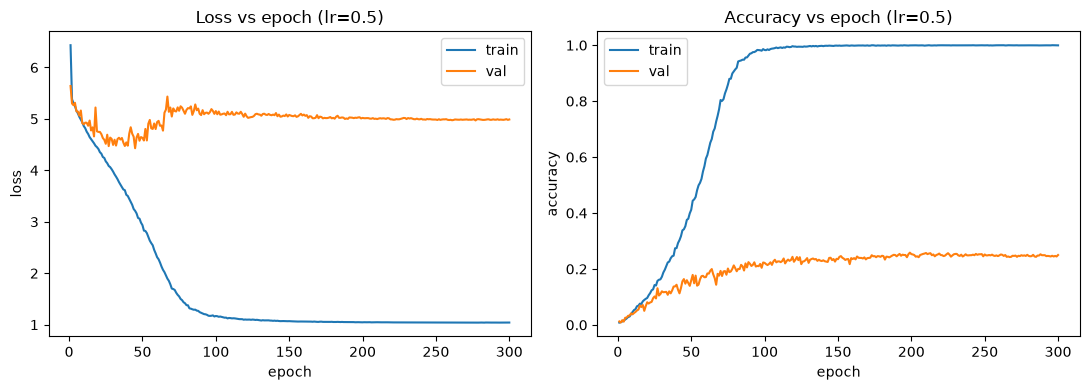

In [21]:
torch.manual_seed(0)
efficientNet = models.efficientnet_v2_s(weights=None).to(device)  # fresh weights
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.5,weight_decay=1*(10**-4))
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs * steps_per_epoch)  # stepped per batch in train()
training_loss,training_accuracy,val_loss,val_acc = train(X_train,Y_train,criterion,optimizer,scheduler,num_epochs,0.01,X_val,Y_val)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.5)

Section 6: Data Augmentation

In [22]:
from torch.utils.data import DataLoader
train_dataset = [{"imgs": X_train[i], "label": Y_train[i]} for i in range(len(X_train))]

mixup = v2.MixUp(alpha=0.2,num_classes=len(K))

def collate(batch):
    return torch.utils.data.default_collate(batch) 

train_dataloader = DataLoader(train_dataset,batch_size,collate_fn=collate,shuffle=True) # type: ignore

In [23]:
def train(data_loader:torch.utils.data.DataLoader,optimizer:torch.optim.Optimizer,scheduler:torch.optim.lr_scheduler.LRScheduler,criterion:nn.CrossEntropyLoss):
    torch.manual_seed(0)
    losses,accuracy,val_losses,val_accuracy=[],[],[],[]
    for epoch in range(num_epochs):
        efficientNet.train()
        total_loss,correct,n=0,0,0
        for batch in data_loader:
            # batch: {"imgs": uint8 (B,C,H,W), "label": long (B,)}. Augment + normalize first, MixUp needs float images.
            batch = {"imgs": prep(batch["imgs"],train=True), "label": batch["label"]}
            batch = mixup(batch)                      # imgs mixed, label -> soft (B,num_classes)
            x,y = batch["imgs"],batch["label"]
            optimizer.zero_grad(set_to_none=True)
            output = efficientNet(x)
            loss = criterion(output,y)                # CrossEntropyLoss accepts soft targets
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
            total_loss += loss.item() * len(x)
            correct += (output.argmax(1) == y.argmax(1)).sum().item()  # vs dominant class
            n += len(x)
        losses.append(total_loss/n)
        accuracy.append(correct/n)
        vl,va = eval(X_val,Y_val,criterion)           # validation: no MixUp, integer labels
        val_losses.append(vl)
        val_accuracy.append(va)
        print(f'epoch {epoch}: loss {losses[-1]:.4f} acc {accuracy[-1]:.4f} val_loss {vl:.4f} val_acc {va:.4f}')
    return losses,accuracy,val_losses,val_accuracy

epoch 0: loss 5.2000 acc 0.0096 val_loss 4.7950 val_acc 0.0124
epoch 1: loss 4.8314 acc 0.0119 val_loss 4.7820 val_acc 0.0091
epoch 2: loss 4.7952 acc 0.0127 val_loss 4.7777 val_acc 0.0183
epoch 3: loss 4.7826 acc 0.0129 val_loss 4.7649 val_acc 0.0202
epoch 4: loss 4.7666 acc 0.0137 val_loss 4.7488 val_acc 0.0222
epoch 5: loss 4.7357 acc 0.0165 val_loss 4.7072 val_acc 0.0111
epoch 6: loss 4.7085 acc 0.0189 val_loss 4.6509 val_acc 0.0313
epoch 7: loss 4.6892 acc 0.0238 val_loss 4.6434 val_acc 0.0261
epoch 8: loss 4.6658 acc 0.0275 val_loss 4.6206 val_acc 0.0307
epoch 9: loss 4.6434 acc 0.0243 val_loss 4.6136 val_acc 0.0215
epoch 10: loss 4.6325 acc 0.0298 val_loss 4.5900 val_acc 0.0333
epoch 11: loss 4.6248 acc 0.0312 val_loss 4.5841 val_acc 0.0333
epoch 12: loss 4.5917 acc 0.0314 val_loss 4.5864 val_acc 0.0352
epoch 13: loss 4.5748 acc 0.0358 val_loss 4.5668 val_acc 0.0404
epoch 14: loss 4.5609 acc 0.0368 val_loss 4.5215 val_acc 0.0417
epoch 15: loss 4.5343 acc 0.0428 val_loss 4.4953 v

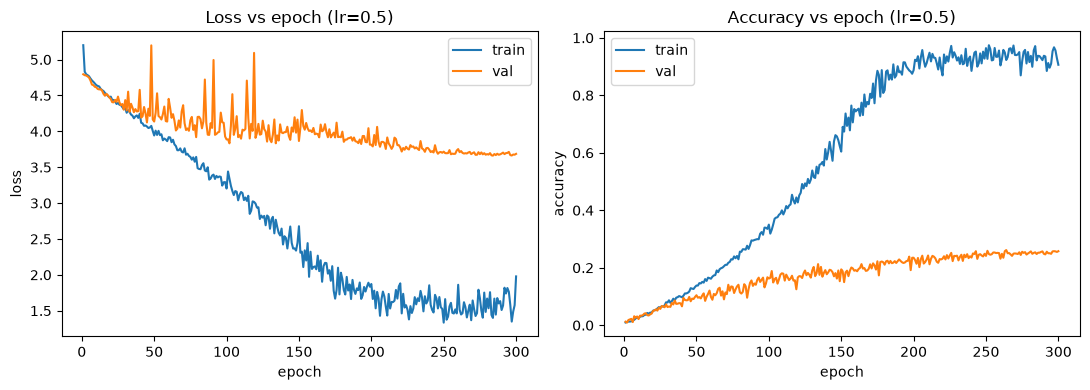

In [24]:
from torch.optim.lr_scheduler import CosineAnnealingLR
torch.manual_seed(0)
num_epochs=300
efficientNet = models.efficientnet_v2_s(weights=None, num_classes=len(K)).to(device)  # fresh weights, 120 outputs so logits match the (B,120) soft MixUp targets
optimizer = torch.optim.SGD(efficientNet.parameters(), lr=0.5,weight_decay=5*(10**-4))
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs * steps_per_epoch)  # stepped per batch in train()
training_loss,training_accuracy,val_loss,val_acc = train(train_dataloader,optimizer,scheduler,criterion)
plot_curves(training_loss,val_loss,training_accuracy,val_acc,lr=0.5)
torch.save(efficientNet.state_dict(), 'models/effnet_mixup.pt')

Testing Setup

In [25]:
testImgs = torch.stack([
    resize(decode_image(f'./data/test/images/{p}.jpg', mode=ImageReadMode.RGB))
        for p in testDf.id
]).to(device)
test_x = norm(testImgs.float()/255)
test_y = torch.tensor([clss_idx[b] for b in testDf.breed],   dtype=torch.long, device=device)
efficientNet.eval()

correct = 0
with torch.no_grad():
    for i in range(0, len(test_x), batch_size):
        out = efficientNet(test_x[i:i+batch_size])
        correct += (out.argmax(1) == test_y[i:i+batch_size]).sum().item()
print('test accuracy', correct / len(test_x))

test accuracy 0.2737940026075619
